# Estonian replication of the male abstraction bias (Fig. 1a)

Replicates the text-based analysis of the paper in Estonian, step for step as in the Dutch replication:

1. load the human concreteness norms of Proos & Aigro (2023) — `data.csv` from the OSF archive (35,979 lemmas, 0–10 scale);
2. load fastText's Estonian word vectors (`cc.et.300.vec`, Common Crawl + Wikipedia, 2M words × 300-d) — the file is streamed, only the rows for the rated words and the seed words are kept, so memory stays low;
3. build a gender axis from seed pairs (Eq. S1 of the supplement: mean of unit(male) − unit(female), re-normalised) and score every rated word by its cosine with that axis (positive = masculine);
4. test whether more masculine words are more abstract (negative correlation), with the same controls, exclusions and seed-pair sensitivity checks as for Dutch;
5. draw the Fig. 1a-style decile figure and save all tables.

Estonian has no gendered pronouns (*tema/ta* covers he and she), so the seed pairs are kinship/role nouns and the adjective pair *mehelik/naiselik*, mirroring the Dutch primary set.

**Requirements:** `numpy pandas scipy statsmodels matplotlib` (`pip install numpy pandas scipy statsmodels matplotlib`). No fastText package is needed for the `.vec` text file.

In [1]:
# ---------------------------------------------------------------- configuration
from pathlib import Path

BASE    = Path.cwd()   # folder holding this notebook
VEC     = BASE / "cc.et.300.vec"                                   # fastText Estonian text vectors
NORMS   = BASE / "data.csv"                                        # Proos & Aigro (2023) OSF file
OUT     = BASE / "results_et"                                      # outputs go here
OUT.mkdir(exist_ok=True)

# fall back to the renamed copy of the norms if that is what is in the folder
if not NORMS.exists() and (BASE / "et-proos-aigro-2023.csv").exists():
    NORMS = BASE / "et-proos-aigro-2023.csv"
for p in (VEC, NORMS):
    assert p.exists(), f"missing file: {p}"

LANGNAME, SCALE = "Estonian", "0–10"

# Seed pairs. Primary = the kinship/role analogues of the paper's five pairs (as in the Dutch
# primary set); extended adds five more kinship/role pairs.
SEEDS = {
    "primary":  [("mees", "naine"), ("poiss", "tüdruk"), ("mehelik", "naiselik"),
                 ("isa", "ema"), ("vend", "õde")],
    "extended": [("mees", "naine"), ("poiss", "tüdruk"), ("mehelik", "naiselik"),
                 ("isa", "ema"), ("vend", "õde"), ("poeg", "tütar"), ("onu", "tädi"),
                 ("kuningas", "kuninganna"), ("härra", "proua"), ("vanaisa", "vanaema")],
}
# Gendered pairs never used as seeds: a valid axis should order the male member above the female one.
VALIDATION = [("peigmees", "pruut"), ("näitleja", "näitlejanna"), ("laulja", "lauljatar"),
              ("sõber", "sõbranna"), ("noormees", "neiu"), ("isand", "emand"),
              ("ristiisa", "ristiema"), ("vanamees", "vanamoor"), ("abielumees", "abielunaine"),
              ("meesterahvas", "naisterahvas"), ("kasuisa", "kasuema"), ("prints", "printsess"),
              ("kuningapoeg", "kuningatütar"), ("vanaonu", "vanatädi"), ("ärimees", "ärinaine"),
              ("mehed", "naised"), ("poisid", "tüdrukud"), ("isad", "emad"), ("vennad", "õed"),
              ("pojad", "tütred")]
# Crude filter for lexically gendered words (gendered morphemes, kinship/role stems), used in one exclusion check.
import re
GENDERED_RE = re.compile(r"(?:mees$|mehe|naine|naise|poiss|tüdruk|isa$|ema$|vend$|õde$|poeg$|tütar|härra|proua|"
                         r"preili|kuningas|kuninganna|prints|onu$|tädi|vanaema|vanaisa|abikaasa|pruut|peigmees|"
                         r"neiu|noormees|mehelik|naiselik|tar$|nna$|lesk|isand|emand)")
print("vectors:", VEC, "\nnorms:  ", NORMS, "\noutputs:", OUT)

vectors: C:\Users\dguilb\Desktop\estonian replication\cc.et.300.vec 
norms:   C:\Users\dguilb\Desktop\estonian replication\data.csv 
outputs: C:\Users\dguilb\Desktop\estonian replication\results_et


In [2]:
# ---------------------------------------------------------------- imports and helpers
import json, sys, time
import numpy as np, pandas as pd
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200); pd.set_option("display.max_colwidth", 80)

def unit(v):
    n = np.linalg.norm(v); return v / n if n > 0 else v

_warned = set()
def gender_axis(lookup, pairs):
    # Eq. S1: mean over pairs of unit(male) - unit(female), re-normalised
    diffs, used = [], []
    for m, f in pairs:
        vm, vf = lookup(m), lookup(f)
        if vm is None or vf is None:
            if (m, f) not in _warned:
                print(f"   seed pair missing in the vectors: ({m}, {f})"); _warned.add((m, f))
            continue
        diffs.append(unit(vm) - unit(vf)); used.append((m, f))
    if not diffs: raise RuntimeError("no seed pairs available in the vectors")
    return unit(np.mean(diffs, axis=0)), used

def score_terms(lookup, axis, words):
    g = np.full(len(words), np.nan)
    for i, w in enumerate(words):
        v = lookup(w)
        if v is not None: g[i] = float(unit(v) @ axis)
    return g

def fisher_ci(r, n):
    if n < 4 or abs(r) >= 1: return (np.nan, np.nan)
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3); q = stats.norm.ppf(0.975)
    return tuple(np.tanh([z - q * se, z + q * se]))

def zs(x):
    x = np.asarray(x, float); return (x - np.nanmean(x)) / np.nanstd(x)

def describe(df, label):
    d = df.dropna(subset=["gender", "conc"])
    r, p = stats.pearsonr(d.gender, d.conc); lo, hi = fisher_ci(r, len(d)); rho, _ = stats.spearmanr(d.gender, d.conc)
    return dict(specification=label, r=r, ci_lo=lo, ci_hi=hi, p=p, rho=rho, n=len(d))

def ols_beta(df, controls, label):
    # standardised coefficient on concreteness (HC1 SEs) in a regression of z(gender) on z(concreteness) + controls
    cols = ["conc"] + controls
    d = df.dropna(subset=["gender"] + cols)
    X = sm.add_constant(np.column_stack([zs(d[c]) for c in cols]))
    res = sm.OLS(zs(d.gender), X).fit(cov_type="HC1"); ci = res.conf_int()[1]
    return dict(specification=label, r=res.params[1], ci_lo=ci[0], ci_hi=ci[1], p=res.pvalues[1], rho=np.nan, n=len(d))

def deciles(df):
    d = df.dropna(subset=["gender", "conc"]).copy()
    d["decile"] = pd.qcut(d.gender.rank(method="first"), 10, labels=range(1, 11)).astype(int)
    return d.groupby("decile").conc.agg(["mean", "count"]).reset_index()

def validation_accuracy(lookup, axis, used):
    hits = []
    for m, f in VALIDATION:
        if (m, f) in used: continue
        vm, vf = lookup(m), lookup(f)
        if vm is None or vf is None: continue
        hits.append(float(unit(vm) @ axis) > float(unit(vf) @ axis))
    return (np.mean(hits) if hits else np.nan), len(hits)

## 1. Concreteness norms

In [3]:
norms = pd.read_csv(NORMS, keep_default_na=False, na_values=[""],
                    usecols=lambda c: c in {"lemma", "concreteness_index", "concreteness_sd", "concreteness_ratingcount"})
norms = norms.rename(columns={"lemma": "word", "concreteness_index": "conc", "concreteness_sd": "conc_sd",
                              "concreteness_ratingcount": "n_ratings"})
for c in ("conc", "conc_sd", "n_ratings"):
    norms[c] = pd.to_numeric(norms[c], errors="coerce")
norms["word"] = norms.word.astype(str).str.strip()
norms = norms[(norms.word != "") & norms.conc.notna()]
norms = norms.groupby("word", as_index=False).agg(conc=("conc", "mean"), conc_sd=("conc_sd", "mean"), n_ratings=("n_ratings", "sum"))
norms["length"] = norms.word.str.len()
print(f"{len(norms):,} rated words; concreteness mean {norms.conc.mean():.2f} (sd {norms.conc.std():.2f}) on a {SCALE} scale")
norms.sample(8, random_state=1)

35,979 rated words; concreteness mean 6.39 (sd 1.88) on a 0–10 scale


,word,conc,conc_sd,n_ratings,length
23296,rahastamissüsteem,5.733333,3.155343,12,17
11029,konkreetsemalt,2.888182,1.603383,12,14
16872,metsapoliitika,5.076667,4.332799,11,14
18133,müügitegevus,5.635556,2.366084,11,12
311,abielluja,8.240000,1.992019,11,9
23399,rahvalaul,7.613000,2.971924,11,9
13731,lastekaup,6.180000,2.502101,11,9
25468,seksuaalvahekord,7.832727,2.443408,11,16


## 2. fastText Estonian vectors

`cc.et.300.vec` is a 2,000,001-line text file (header + one word per line, in corpus-frequency order). It is read once from top to bottom and only the rows for rated words, seed words and validation words are kept (~36k vectors). The line rank is kept as the word-frequency measure for the frequency control.

In [4]:
needed = set(norms.word) | {w for s in SEEDS.values() for p in s for w in p} | {w for p in VALIDATION for w in p}
needed |= {w.lower() for w in needed}

t0 = time.time()
vec, rank, dim, n_lines = {}, {}, None, 0
with open(VEC, "rt", encoding="utf8", errors="ignore") as f:
    for i, line in enumerate(f):
        p = line.rstrip("\r\n").split(" ")
        if i == 0 and len(p) == 2:
            dim = int(p[1]); continue
        if dim is None: dim = len(p) - 1
        w = " ".join(p[:len(p) - dim])
        if w in needed and w not in vec:
            vec[w] = np.array(p[len(p) - dim:], dtype=np.float32); rank[w] = i
        n_lines = i
print(f"scanned {n_lines:,} lines in {time.time()-t0:.0f} s; kept {len(vec):,} vectors ({dim}-d)")

def lookup(w):
    v = vec.get(w)
    return v if v is not None else vec.get(w.lower())

def logfreq(w):
    r = rank.get(w, rank.get(w.lower()))
    return -np.log(r) if r else np.nan      # file order = frequency order; higher = more frequent

norms["logfreq"] = [logfreq(w) for w in norms.word]
covered = norms.word.map(lambda w: lookup(w) is not None)
print(f"{covered.sum():,} of {len(norms):,} rated words ({covered.mean():.1%}) have a vector")
missing = sorted({p for s in SEEDS.values() for p in s if lookup(p[0]) is None or lookup(p[1]) is None})
print("seed pairs missing from the vectors:", missing or "none")

scanned 2,000,000 lines in 72 s; kept 33,171 vectors (300-d)
33,031 of 35,979 rated words (91.8%) have a vector
seed pairs missing from the vectors: none


## 3. Gender scores and the main test

For each seed set the gender axis is built, every rated word is scored, and the association with concreteness is estimated under the specifications used in the Dutch replication (Supplementary Tables for Dutch): correlations with Fisher 95% CIs, exclusions, HC1 regressions with frequency and length, frequency quintiles, and a reliably-rated subset (rater SD at or below the median). A negative sign means more masculine words are more abstract.

In [5]:
rows, dec_tables, seeds_used, scores = [], [], {}, norms[["word", "conc"]].copy()
for pset, pairs in SEEDS.items():
    axis, used = gender_axis(lookup, pairs); seeds_used[pset] = used
    g = score_terms(lookup, axis, norms.word.tolist())
    df = norms.copy(); df["gender"] = g; scores[f"gender::{pset}"] = g
    acc, nval = validation_accuracy(lookup, axis, used)
    print(f"seeds={pset}: {len(used)}/{len(pairs)} pairs; {int(np.isfinite(g).sum()):,}/{len(df):,} words scored; "
          f"held-out gendered pairs ordered male > female: {acc:.2f} (n={nval})")
    R = [describe(df, "all terms (no controls)")]
    seedset = {w for p in used for w in p}
    R.append(describe(df[~(df.word.str.contains(GENDERED_RE) | df.word.isin(seedset))], "excl. lexically gendered terms + seeds"))
    for q in (0.05, 0.10):
        thr = df.gender.abs().quantile(1 - q)
        R.append(describe(df[df.gender.abs() < thr], f"excl. {int(q*100)}% most gendered terms"))
    R.append(describe(df[df.conc_sd <= df.conc_sd.median()], "rater s.d. of concreteness <= median (reliably rated)"))
    R.append(ols_beta(df, [], "OLS: no controls"))
    R.append(ols_beta(df, ["logfreq"], "OLS: + log frequency (fastText rank)"))
    R.append(ols_beta(df, ["length"], "OLS: + length"))
    R.append(ols_beta(df, ["logfreq", "length"], "OLS: + frequency + length"))
    dq = df.dropna(subset=["logfreq", "gender"]).copy()
    dq["fq"] = pd.qcut(dq.logfreq.rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
    for k in range(1, 6):
        R.append(describe(dq[dq.fq == k], f"frequency quintile {k}" + (" (least frequent)" if k == 1 else " (most frequent)" if k == 5 else "")))
    for r_ in R: r_.update(seeds=pset, validation_accuracy=acc, validation_pairs=nval)
    rows += R
    dd = deciles(df); dd["seeds"] = pset; dec_tables.append(dd)

S = pd.DataFrame(rows)[["seeds", "specification", "r", "ci_lo", "ci_hi", "p", "rho", "n", "validation_accuracy", "validation_pairs"]]
S.round(4)

seeds=primary: 5/5 pairs; 33,031/35,979 words scored; held-out gendered pairs ordered male > female: 1.00 (n=20)
seeds=extended: 10/10 pairs; 33,031/35,979 words scored; held-out gendered pairs ordered male > female: 1.00 (n=20)


,seeds,specification,r,ci_lo,ci_hi,p,rho,n,validation_accuracy,validation_pairs
0,primary,all terms (no controls),-0.1244,-0.1350,-0.1138,0.0,-0.1237,33031,1.0,20
1,primary,excl. lexically gendered terms + seeds,-0.1239,-0.1346,-0.1131,0.0,-0.1235,32263,1.0,20
2,primary,excl. 5% most gendered terms,-0.1434,-0.1543,-0.1326,0.0,-0.1369,31379,1.0,20
3,primary,excl. 10% most gendered terms,-0.1482,-0.1593,-0.1371,0.0,-0.1417,29727,1.0,20
4,primary,rater s.d. of concreteness <= median (reliably rated),-0.1384,-0.1533,-0.1235,0.0,-0.1480,16609,1.0,20
5,primary,OLS: no controls,-0.1244,-0.1354,-0.1134,0.0,NaN,33031,1.0,20
6,primary,OLS: + log frequency (fastText rank),-0.1261,-0.1371,-0.1151,0.0,NaN,33031,1.0,20
7,primary,OLS: + length,-0.1261,-0.1371,-0.1152,0.0,NaN,33031,1.0,20
8,primary,OLS: + frequency + length,-0.1269,-0.1379,-0.1159,0.0,NaN,33031,1.0,20
9,primary,frequency quintile 1 (least frequent),-0.1073,-0.1311,-0.0834,0.0,-0.1036,6607,1.0,20


## 4. Decile pattern and figure

Mean concreteness by gender-score decile (1 = most feminine, 10 = most masculine):


seeds,extended,primary
decile,,
1,7.22,7.09
2,6.77,6.68
3,6.51,6.50
4,6.37,6.39
5,6.18,6.31
6,6.17,6.16
7,6.09,6.13
8,6.05,6.08
9,6.09,6.13


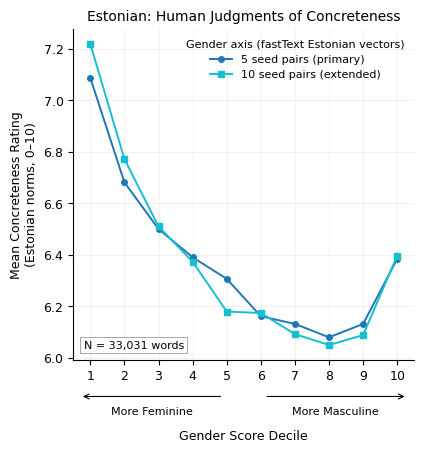

saved C:\Users\dguilb\Desktop\estonian replication\results_et\figS_estonian_replication.png


In [6]:
DEC = pd.concat(dec_tables, ignore_index=True)
print("Mean concreteness by gender-score decile (1 = most feminine, 10 = most masculine):")
display(DEC.pivot_table(index="decile", columns="seeds", values="mean").round(2))

n_words = int(S[(S.seeds == "primary") & (S.specification == "all terms (no controls)")].n.iloc[0])
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(4.4, 4.3))
for pset, label, col, mk in [("primary", "5 seed pairs (primary)", "#1f77b4", "o"), ("extended", "10 seed pairs (extended)", "#17becf", "s")]:
    d = DEC[DEC.seeds == pset].sort_values("decile")
    ax.plot(d.decile, d["mean"], marker=mk, ms=4, lw=1.4, color=col, label=label)
ax.set_xticks(range(1, 11)); ax.set_xlim(0.5, 10.5)
ax.set_ylabel(f"Mean Concreteness Rating\n({LANGNAME} norms, {SCALE})")
ax.set_title(f"{LANGNAME}: Human Judgments of Concreteness", fontsize=10); ax.grid(alpha=0.25, lw=0.5)
ax.text(0.03, 0.03, f"N = {n_words:,} words", ha="left", va="bottom", transform=ax.transAxes, fontsize=8,
        bbox=dict(boxstyle="square,pad=0.3", fc="white", ec="0.6", lw=0.6))
ax.legend(loc="best", fontsize=8, frameon=False, title=f"Gender axis (fastText {LANGNAME} vectors)", title_fontsize=8)
ax.set_xlabel("Gender Score Decile", labelpad=34)
ax.annotate("", xy=(0.02, -0.11), xytext=(0.44, -0.11), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", lw=0.8))
ax.annotate("", xy=(0.98, -0.11), xytext=(0.56, -0.11), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", lw=0.8))
ax.text(0.23, -0.14, "More Feminine", ha="center", va="top", transform=ax.transAxes, fontsize=8)
ax.text(0.77, -0.14, "More Masculine", ha="center", va="top", transform=ax.transAxes, fontsize=8)
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"figS_estonian_replication.{ext}", dpi=300, bbox_inches="tight")
plt.show()
print("saved", OUT / "figS_estonian_replication.png")

## 5. Sensitivity to the seed pairs

The same checks that mattered for Dutch: the primary set, the extended set, each leave-one-pair-out axis, every single pair on its own, and the first principal component of the ten unit-normalised pair differences (Bolukbasi et al.), with the most feminine and most masculine words under each axis so that a contaminated axis can be recognised.

In [7]:
prim, ext = SEEDS["primary"], SEEDS["extended"]
specs = {"primary set (5 pairs)": prim, "extended set (10 pairs)": ext}
for p in prim: specs[f"primary minus {p[0]}/{p[1]}"] = [q for q in prim if q != p]
for p in ext: specs[f"single pair {p[0]}/{p[1]}"] = [p]
PS = []
for label, pairs in specs.items():
    try: axis, used = gender_axis(lookup, pairs)
    except RuntimeError: continue
    g = score_terms(lookup, axis, norms.word.tolist()); ok = np.isfinite(g)
    r, p = stats.pearsonr(g[ok], norms.conc.values[ok]); lo, hi = fisher_ci(r, ok.sum())
    d = pd.DataFrame({"w": norms.word, "g": g}).dropna().sort_values("g")
    PS.append(dict(specification=label, n_pairs=len(used), r=r, ci_lo=lo, ci_hi=hi, p=p, n=int(ok.sum()),
                   most_female=", ".join(d.w.head(8)), most_male=", ".join(d.w.tail(8)[::-1])))
# PC1 of the extended set (uncentred SVD of unit pair differences, sign-aligned with their mean)
D = np.vstack([unit(unit(lookup(m)) - unit(lookup(f))) for m, f in ext if lookup(m) is not None and lookup(f) is not None])
U, s, Vt = np.linalg.svd(D, full_matrices=False); pc1 = Vt[0]; pc1 = pc1 if D.mean(0) @ pc1 > 0 else -pc1
g = score_terms(lookup, unit(pc1), norms.word.tolist()); ok = np.isfinite(g)
r, p = stats.pearsonr(g[ok], norms.conc.values[ok]); lo, hi = fisher_ci(r, ok.sum())
d = pd.DataFrame({"w": norms.word, "g": g}).dropna().sort_values("g")
PS.append(dict(specification=f"PC1 of extended set (var. expl. {s[0]**2/(s**2).sum():.2f}; loadings {np.round(D@pc1,2).tolist()})",
               n_pairs=len(D), r=r, ci_lo=lo, ci_hi=hi, p=p, n=int(ok.sum()),
               most_female=", ".join(d.w.head(8)), most_male=", ".join(d.w.tail(8)[::-1])))
PS = pd.DataFrame(PS)
PS[["specification", "n_pairs", "r", "ci_lo", "ci_hi", "n", "most_female", "most_male"]].round(3)

,specification,n_pairs,r,ci_lo,ci_hi,n,most_female,most_male
0,primary set (5 pairs),5,-0.124,-0.135,-0.114,33031,"sõbranna, õde, kleit, pulmakleit, rootslanna, ämmaemand, meik, eksnaine","vend, roolimees, raudmees, ülem, pealik, vilemees, nooremseersant, mängumees"
1,extended set (10 pairs),10,-0.141,-0.151,-0.130,33031,"sõbranna, tädi, rootslanna, kaaslanna, eksnaine, sünnitusmaja, näitlejanna, ...","vend, onu, pojapoeg, vilemees, poeg, ülem, vanemveebel, jahimees"
2,primary minus mees/naine,4,-0.165,-0.175,-0.154,33031,"kleit, sõbranna, õde, meik, pulmakleit, rootslanna, pärnulanna, naiselik","vend, poeg, pojapoeg, pealik, isa, seenior, etteotsa, ülem"
3,primary minus poiss/tüdruk,4,-0.148,-0.158,-0.137,33031,"õde, ämmaemand, sõbranna, kleit, eksnaine, rootslanna, meditsiiniõde, sünnit...","vend, raudmees, roolimees, mängumees, vilemees, põhimees, ülem, pealik"
4,primary minus mehelik/naiselik,4,-0.124,-0.135,-0.114,33031,"õde, sõbranna, meditsiiniõde, kleit, ämmaemand, eksnaine, kaaslanna, rootslanna","vend, roolimees, pealik, vilemees, tehnikadirektor, raudmees, ülem, riigimees"
5,primary minus isa/ema,4,-0.052,-0.062,-0.041,33031,"õde, pulmakleit, kleit, meik, sõbranna, naiselik, rootslanna, ämmaemand","vend, raudmees, roolimees, mängumees, varumees, vilemees, ääremängija, seenior"
6,primary minus vend/õde,4,-0.112,-0.123,-0.101,33031,"naiselik, sõbranna, kleit, parfüüm, pulmakleit, rootslanna, meik, pruutkleit","ülem, roolimees, vanemveebel, julgeolekumees, nooremseersant, riigimees, vil..."
7,single pair mees/naine,1,0.054,0.043,0.064,33031,"naine, ema, emadus, eksnaine, krahvinna, raseduskuu, rasedus, poolõde","raudmees, varumees, vilemees, mees, ekskavaator, tsiklimees, keskväljamees, ..."
8,single pair poiss/tüdruk,1,-0.007,-0.018,0.004,33031,"tüdruk, meik, kangelanna, brünett, seksikas, tüdruksõber, parfüüm, parfümeeria","poiss, paipoiss, pojapoeg, seenior, karjapoiss, koolipoiss, naabripoiss, vend"
9,single pair mehelik/naiselik,1,-0.055,-0.066,-0.044,33031,"naiselik, naiselikkus, parfüüm, meigikunstnik, naiselikum, lavendel, peakuns...","mehelik, riigimehelikult, ahelik, riigimehelik, võimeline, suurtükituli, lii..."


## 6. Save everything

`stats_et.csv`, `deciles_et.csv`, `pole_sensitivity_et.csv`, `scores_et.csv` (per-word gender scores) and `seeds_et.json` go to the `results_et` folder next to this notebook, alongside the figure.

In [8]:
S_out = S.copy(); S_out.insert(0, "model", VEC.name); S_out.insert(0, "language", LANGNAME)
S_out.to_csv(OUT / "stats_et.csv", index=False)
DEC.to_csv(OUT / "deciles_et.csv", index=False)
PS.to_csv(OUT / "pole_sensitivity_et.csv", index=False)
scores.to_csv(OUT / "scores_et.csv", index=False)
json.dump(seeds_used, open(OUT / "seeds_et.json", "w", encoding="utf8"), ensure_ascii=False, indent=1)
print("written to", OUT)
for f in sorted(OUT.iterdir()): print("  ", f.name)

written to C:\Users\dguilb\Desktop\estonian replication\results_et
   deciles_et.csv
   figS_estonian_replication.pdf
   figS_estonian_replication.png
   pole_sensitivity_et.csv
   scores_et.csv
   seeds_et.json
   stats_et.csv
